# The Weak Yen Squeeze on Coffee

**Question:** How much of the rise in Japanese coffee prices comes from global coffee markets vs. the weak yen, and how long does it take for import costs to reach consumers?

**Data:** Japan Customs (green coffee imports), FRED (IMF coffee prices, yen to dollar exchange rate), and the Statistics Bureau of Japan (Consumer Price Index and store prices by city). See `DATA_NOTES.md` for sources, units, and caveats.

**Notebook outline**
1. Setup
2. Load and check the world price data (FRED)
3. Merge and convert to yen per kg
4. Dollar price vs. yen price (index chart)
5. Japan's actual import cost vs. world prices
6. How long until import costs change? (lag)
7. World coffee prices vs. the exchange rate (the main breakdown)
8. Did store and cafe prices follow?
9. City comparison: Naha vs. Tokyo, Kyoto, and Sapporo
10. Summary of findings

## 1. Setup

In [1]:
# Libraries used in this notebook
import pandas as pd
import matplotlib.pyplot as plt

# Path to the raw data, relative to the notebooks folder
# ".." means "go up one folder" to the main project folder
DATA = "../data/raw"

# Number of pounds in one kilogram (used to convert world prices)
LB_PER_KG = 2.20462

## 2. Load and check the world price data (FRED)

Each file is loaded, its date column converted to real dates, its columns renamed to clear names that include the unit, and then checked for size, missing values, and date range.

In [2]:
# ---------- Arabica ----------
# Source: IMF (International Monetary Fund) via FRED, series PCOFFOTMUSDM, U.S. cents per pound, monthly
arabica = pd.read_csv(DATA + "/arabica_price.csv")

# Convert dates to real dates and give columns clear names
arabica["observation_date"] = pd.to_datetime(arabica["observation_date"])
arabica = arabica.rename(columns={
    "observation_date": "month",
    "PCOFFOTMUSDM": "arabica_cents_lb"
})

# Health check: size, missing values, date range
print("ARABICA")
print("Shape:", arabica.shape)
print("Missing values:", arabica.isna().sum().sum())
print("Dates:", arabica["month"].min().date(), "to", arabica["month"].max().date())
print()

# ---------- Robusta ----------
# Source: IMF via FRED, series PCOFFROBUSDM, U.S. cents per pound, monthly
robusta = pd.read_csv(DATA + "/robusta_price.csv")

robusta["observation_date"] = pd.to_datetime(robusta["observation_date"])
robusta = robusta.rename(columns={
    "observation_date": "month",
    "PCOFFROBUSDM": "robusta_cents_lb"
})

print("ROBUSTA")
print("Shape:", robusta.shape)
print("Missing values:", robusta.isna().sum().sum())
print("Dates:", robusta["month"].min().date(), "to", robusta["month"].max().date())
print()

# ---------- Yen per U.S. dollar ----------
# Source: Federal Reserve Board via FRED, series EXJPUS, monthly average
yen = pd.read_csv(DATA + "/yendollar_rate.csv")

yen["observation_date"] = pd.to_datetime(yen["observation_date"])
yen = yen.rename(columns={
    "observation_date": "month",
    "EXJPUS": "yen_per_usd"
})

print("YEN PER DOLLAR")
print("Shape:", yen.shape)
print("Missing values:", yen.isna().sum().sum())
print("Dates:", yen["month"].min().date(), "to", yen["month"].max().date())

ARABICA
Shape: (193, 2)
Missing values: 0
Dates: 2010-07-01 to 2026-07-01

ROBUSTA
Shape: (199, 2)
Missing values: 0
Dates: 2010-01-01 to 2026-07-01

YEN PER DOLLAR
Shape: (201, 2)
Missing values: 0
Dates: 2010-01-01 to 2026-09-01


## 3. Merge and convert to yen per kg

The three files are combined into one table, one row per month. An **outer** merge (like a SQL FULL OUTER JOIN) keeps every month from every file, so gaps stay visible instead of being silently dropped.

In [3]:
# Merge the three tables on the "month" column
fred = (arabica
        .merge(robusta, on="month", how="outer")
        .merge(yen, on="month", how="outer"))

# Keep January 2010 onward, put the months in order, and renumber the rows
fred = fred[fred["month"] >= "2010-01-01"].sort_values("month").reset_index(drop=True)

# Health check on the merged table
print("Shape:", fred.shape)
print()
print("Missing values per column:")
print(fred.isna().sum())

Shape: (201, 4)

Missing values per column:
month               0
arabica_cents_lb    8
robusta_cents_lb    2
yen_per_usd         0
dtype: int64


The gaps are expected: the Arabica file starts in July 2010, and each source updates on its own schedule, so the latest months differ.

Next, world prices (U.S. cents per pound) are converted to yen per kg, the same unit as Japan's import data:
1. cents to dollars: divide by 100
2. per pound to per kg: multiply by 2.20462
3. dollars to yen: multiply by that month's exchange rate

In [4]:
# U.S. cents per pound -> U.S. dollars per kg
fred["arabica_usd_kg"] = fred["arabica_cents_lb"] / 100 * LB_PER_KG
fred["robusta_usd_kg"] = fred["robusta_cents_lb"] / 100 * LB_PER_KG

# U.S. dollars per kg -> yen per kg, using each month's exchange rate
fred["arabica_yen_kg"] = fred["arabica_usd_kg"] * fred["yen_per_usd"]
fred["robusta_yen_kg"] = fred["robusta_usd_kg"] * fred["yen_per_usd"]

# Sanity check: compare one early month and one recent month
# pd.to_datetime turns the text into real dates, so they match the "month" column's type
check_months = pd.to_datetime(["2015-01-01", "2025-01-01"])
# set_index("month") moves the dates out of the way so .round(1) only rounds the numbers
fred[fred["month"].isin(check_months)].set_index("month").round(1)

,arabica_cents_lb,robusta_cents_lb,yen_per_usd,arabica_usd_kg,robusta_usd_kg,arabica_yen_kg,robusta_yen_kg
month,,,,,,,
2015-01-01,189.6,97.9,118.2,4.2,2.2,494.3,255.2
2025-01-01,353.9,244.9,156.5,7.8,5.4,1221.0,845.0


## 4. Dollar price vs. yen price

Both prices are converted to an **index** (2015 average = 100) so they share one scale, even though one is in dollars and the other in yen. The units cancel out, leaving a ratio: 150 means "50% higher than the 2015 average."

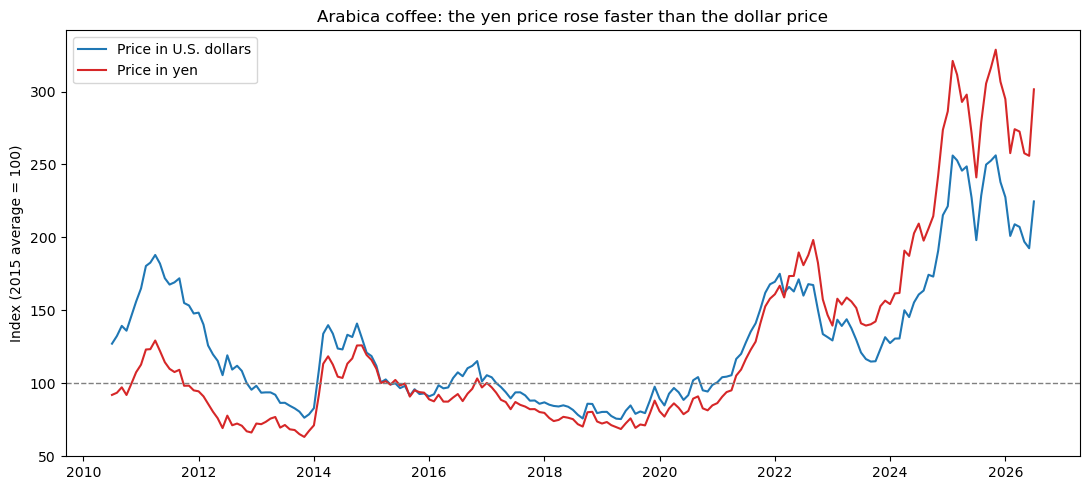

In [5]:
# ---------- Index chart (dollar price vs. yen price) ----------
# Baseline year: 2015 (2015 average = 100)
# Why 2015:
#   - Complete data: every series has all 12 months in 2015
#     (the Arabica file is missing January to June 2010)
#   - A "normal" year: after the 2013-2014 Abenomics yen drop, before COVID (2020),
#     the Brazil frost (2021), and the yen slide that began in 2022
#   - The 2015 exchange rate (about 121 yen per dollar) sits near the middle of the
#     2010-2026 range, so it doesn't exaggerate or hide the yen's effect
#   - A full-year average is steadier than a single month
# Note: both lines equal 100 in 2015 by design, so the gap between them shows how much
# the exchange rate changed compared with 2015. A different baseline would shift the picture.

# Use the 2015 average as the baseline (2015 = 100)
base = fred[fred["month"].dt.year == 2015]

# Index each series: 100 means "same as the 2015 average", 200 means "double"
fred["arabica_usd_index"] = fred["arabica_usd_kg"] / base["arabica_usd_kg"].mean() * 100
fred["arabica_yen_index"] = fred["arabica_yen_kg"] / base["arabica_yen_kg"].mean() * 100

# Plot both lines on the same scale
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(fred["month"], fred["arabica_usd_index"], label="Price in U.S. dollars", color="tab:blue")
ax.plot(fred["month"], fred["arabica_yen_index"], label="Price in yen", color="tab:red")

# Reference line at 100 (the 2015 level)
ax.axhline(100, color="gray", linestyle="--", linewidth=1)

ax.set_title("Arabica coffee: the yen price rose faster than the dollar price")
ax.set_ylabel("Index (2015 average = 100)")
ax.legend()
plt.tight_layout()
plt.show()

**What it shows:** in 2011 to 2013, a strong yen (about 80 yen per dollar) shielded Japan from a global coffee price spike: the dollar price rose sharply, but the yen price rose much less. From 2015 to 2021, the two lines moved together. Since 2022, the situation reversed: the yen price has risen well above the dollar price because each dollar now costs more yen.

**In one line:** the yen used to protect Japanese coffee buyers; now it makes things worse.

## 5. Japan's actual import cost vs. world prices

This checks an assumption: green coffee is priced internationally in U.S. dollars (based on ICE benchmark contracts), so Japan's real import cost should follow world prices converted to yen. Japan's import cost is a **blend** of Arabica and Robusta from many countries, so it should sit between the two world prices.

In [6]:
# ---------- Japan green coffee imports ----------
# Source: Japan Customs, Trade Statistics of Japan, HS 0901.11, monthly total
# yen_per_kg = value paid (including shipping and insurance) / quantity
imports = pd.read_csv(DATA + "/japan_green_coffee_imports_2010_2026.csv")

# Convert "2010-01" text into real dates (first day of each month, matching the FRED table)
imports["month"] = pd.to_datetime(imports["month"])

# Keep only the columns needed, with a clear name for the price
imports = imports[["month", "quantity_kg", "yen_per_kg"]].rename(
    columns={"yen_per_kg": "import_yen_kg"}
)

# Health check: size, missing values, date range
print("IMPORTS")
print("Shape:", imports.shape)
print("Missing values:", imports.isna().sum().sum())
print("Dates:", imports["month"].min().date(), "to", imports["month"].max().date())

IMPORTS
Shape: (200, 3)
Missing values: 0
Dates: 2010-01-01 to 2026-08-01


Shape: (201, 12)
arabica_yen_kg    8
robusta_yen_kg    2
import_yen_kg     1
dtype: int64


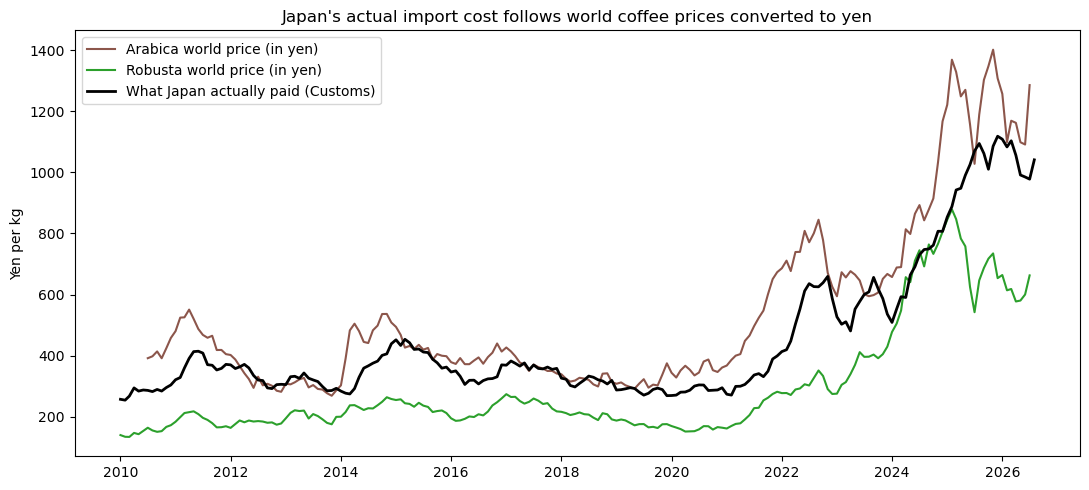

In [7]:
# Add Japan's actual import cost to the FRED table, matched by month
# how="outer" keeps every month from both tables, so any gaps stay visible
combined = fred.merge(imports, on="month", how="outer").sort_values("month").reset_index(drop=True)

# Health check: which columns have gaps after the merge?
print("Shape:", combined.shape)
print(combined[["arabica_yen_kg", "robusta_yen_kg", "import_yen_kg"]].isna().sum())

# Chart: world prices in yen vs. what Japan actually paid, all in yen per kg
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(combined["month"], combined["arabica_yen_kg"], label="Arabica world price (in yen)", color="tab:brown")
ax.plot(combined["month"], combined["robusta_yen_kg"], label="Robusta world price (in yen)", color="tab:green")
ax.plot(combined["month"], combined["import_yen_kg"], label="What Japan actually paid (Customs)", color="black", linewidth=2)

ax.set_title("Japan's actual import cost follows world coffee prices converted to yen")
ax.set_ylabel("Yen per kg")
ax.legend()
plt.tight_layout()
plt.show()

**What it shows:** Japan's import cost moves closely with world prices in yen and sits between Robusta and Arabica in most months, as expected for a blend. This supports the assumption that Japan effectively buys coffee at dollar prices converted at the exchange rate.

## 6. How long until import costs change?

Comparing price *levels* can be misleading, because two prices that both rise over 16 years always look related. So this compares **monthly changes**: when the world price moves, does Japan's import cost move in the same month, or later?

In [8]:
# Monthly % change: how much each price moved compared with the month before
# fill_method=None: don't fill missing months with old values (that would create fake 0% changes)
combined["import_change"] = combined["import_yen_kg"].pct_change(fill_method=None)
combined["arabica_yen_change"] = combined["arabica_yen_kg"].pct_change(fill_method=None)

# Same month: close to 0 means no same-month reaction
same_month = combined["import_change"].corr(combined["arabica_yen_change"])

# 3 months apart: .shift(3) compares each month's import change with the world change 3 months earlier
three_months = combined["import_change"].corr(combined["arabica_yen_change"].shift(3))

print("Correlation, same month:     ", round(same_month, 2))
print("Correlation, 3 months later: ", round(three_months, 2))

Correlation, same month:      0.05
Correlation, 3 months later:  0.39


**What it shows:** almost no same-month relationship, but a much stronger one three months later. Japan's import cost reacts to world coffee prices about **3 months** later, which fits the time needed for contracts, shipping, and customs clearance. (Trying 1, 2, 4, and 5 months gives lower values; 3 months is the peak.)

**Practical takeaway:** a roaster watching world coffee prices and the yen gets about a three-month warning before its costs change.

## 7. World coffee prices vs. the exchange rate (the main breakdown)

To split the rise in Japan's import cost into two causes, ask a "what if" question: *what would Japan have paid if the yen had stayed at its 2015 level?*
- The rise from 2015 up to the "what if" price = the effect of **world coffee prices**
- The gap between the "what if" price and what Japan actually paid = the effect of the **exchange rate**

The two parts add up exactly to the total change since 2015. Yearly averages are used to smooth out month-to-month noise.

In [9]:
# Add a "year" column from the month
combined["year"] = combined["month"].dt.year

# Average import cost (yen per kg) and exchange rate (yen per dollar) for each year
yearly = combined.groupby("year")[["import_yen_kg", "yen_per_usd"]].mean()

# Keep 2015 onward, since 2015 is the baseline
yearly = yearly.loc[2015:]

yearly.round(1)

,import_yen_kg,yen_per_usd
year,,
2015,411.3,121.0
2016,329.5,108.8
2017,365.5,112.1
2018,317.5,110.4
2019,285.8,109.0
2020,288.1,106.8
2021,326.7,109.8
2022,560.3,131.5
2023,563.4,140.5


In [10]:
# ---------- Split the rise in import cost into two causes ----------
# Baseline year: 2015, the same as the index chart in section 4 (see the justification there)
# Note: the split depends on the baseline. With a 2021 baseline (just before the yen
# began falling), the exchange rate's share of the 2025 increase rises from about 32% to about 39%.

# Japan's import cost in U.S. dollars per kg (yen price / exchange rate)
# This is an estimate: it uses yearly average exchange rates, while individual shipments
# were paid at the rate on their own dates (and some importers hedge their currency risk)
yearly["import_usd_kg"] = yearly["import_yen_kg"] / yearly["yen_per_usd"]

# Baseline values from 2015
base_yen_price = yearly.loc[2015, "import_yen_kg"]
base_fx = yearly.loc[2015, "yen_per_usd"]

# "What if" price: this year's dollar price, but converted at the 2015 exchange rate
yearly["whatif_yen_kg"] = yearly["import_usd_kg"] * base_fx

# Split the change since 2015 into two parts (in yen per kg)
# coffee_market_effect: change caused by world coffee prices (in dollars)
# exchange_rate_effect: positive = weaker yen raised the cost; negative = stronger yen lowered it
yearly["coffee_market_effect"] = yearly["whatif_yen_kg"] - base_yen_price
yearly["exchange_rate_effect"] = yearly["import_yen_kg"] - yearly["whatif_yen_kg"]

yearly[["import_yen_kg", "whatif_yen_kg", "coffee_market_effect", "exchange_rate_effect"]].round(0)

,import_yen_kg,whatif_yen_kg,coffee_market_effect,exchange_rate_effect
year,,,,
2015,411.0,411.0,0.0,0.0
2016,329.0,367.0,-45.0,-37.0
2017,366.0,394.0,-17.0,-29.0
2018,317.0,348.0,-63.0,-30.0
2019,286.0,317.0,-94.0,-31.0
2020,288.0,327.0,-85.0,-38.0
2021,327.0,360.0,-51.0,-33.0
2022,560.0,516.0,104.0,45.0
2023,563.0,485.0,74.0,78.0


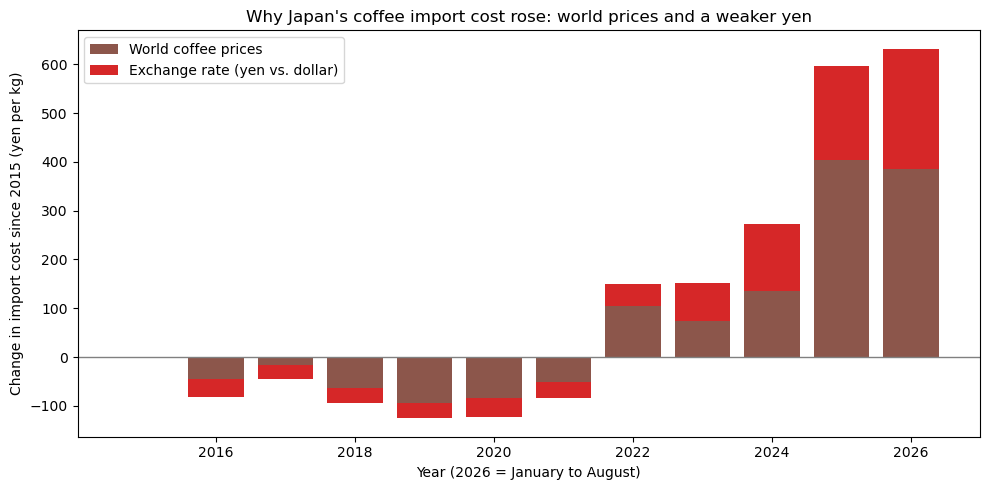

In [11]:
# Stacked bars: each bar is the total change since 2015, split into its two causes
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(yearly.index, yearly["coffee_market_effect"], label="World coffee prices", color="tab:brown")
ax.bar(yearly.index, yearly["exchange_rate_effect"], bottom=yearly["coffee_market_effect"],
       label="Exchange rate (yen vs. dollar)", color="tab:red")

# Line at zero (the 2015 level)
ax.axhline(0, color="gray", linewidth=1)

ax.set_title("Why Japan's coffee import cost rose: world prices and a weaker yen")
ax.set_ylabel("Change in import cost since 2015 (yen per kg)")
ax.set_xlabel("Year (2026 = January to August)")
ax.legend()
plt.tight_layout()
plt.show()

**What it shows:**
- **2016 to 2021:** both effects were negative. Coffee was cheaper than in 2015, and the yen was stronger (about 107 to 112 yen per dollar vs. 121), so both kept Japan's cost below the 2015 level.
- **2022:** both flipped positive at the same time.
- **2023 and 2024:** the exchange rate added about as much as world coffee prices did, roughly half each.
- **2025:** record coffee prices drove most of the jump. Of the 596 yen per kg increase since 2015, about 403 yen (two-thirds) came from world prices and about 193 yen (one-third) from the weaker yen.
- **2026 (January to August):** the yen weakened further, and its share rose to about 40%.

## 8. Did store and cafe prices follow?

Japan's import cost is compared with consumer prices (CPI), all rescaled to **2015 = 100** using yearly averages. The CPI file uses 2025 = 100, so it is rescaled the same way as the index chart: divide by the 2015 average and multiply by 100.

In [12]:
# ---------- Japan Consumer Price Index (CPI) for coffee ----------
# Source: Statistics Bureau of Japan, 2025-base CPI, all Japan, monthly (via e-Stat)
# Values are an index (2025 average = 100), not yen
cpi = pd.read_csv(DATA + "/japan_coffee_cpi_2010_2026.csv")

# Convert "2010-01" text into real dates
cpi["month"] = pd.to_datetime(cpi["month"])

# Health check: size, missing values per column, date range
# (the two "B" columns only start in 2015, so they have 60 missing months)
print("CPI")
print("Shape:", cpi.shape)
print(cpi.isna().sum())
print("Dates:", cpi["month"].min().date(), "to", cpi["month"].max().date())

CPI
Shape: (200, 9)
month                            0
cpi_all_items                    0
cpi_coffee_and_cocoa             0
cpi_instant_coffee               0
cpi_coffee_beans                 0
cpi_coffee_beverage_A            0
cpi_coffee_beverage_B           60
cpi_cafe_coffee_coffee_shop      0
cpi_cafe_coffee_self_service    60
dtype: int64
Dates: 2010-01-01 to 2026-08-01


In [13]:
# Columns to compare: overall inflation, store-bought coffee, and cafe coffee
cpi_cols = ["cpi_all_items", "cpi_coffee_beans", "cpi_instant_coffee", "cpi_cafe_coffee_coffee_shop"]

# Yearly averages for the CPI columns
cpi["year"] = cpi["month"].dt.year
cpi_yearly = cpi.groupby("year")[cpi_cols].mean()

# Add Japan's yearly import cost from section 7
cpi_yearly["import_cost"] = yearly["import_yen_kg"]

# Keep 2015 onward and rescale every column so 2015 = 100
cpi_yearly = cpi_yearly.loc[2015:]
cpi_index = cpi_yearly / cpi_yearly.loc[2015] * 100

cpi_index.round(0)

,cpi_all_items,cpi_coffee_beans,cpi_instant_coffee,cpi_cafe_coffee_coffee_shop,import_cost
year,,,,,
2015,100.0,100.0,100.0,100.0,100.0
2016,100.0,99.0,104.0,100.0,80.0
2017,100.0,96.0,105.0,101.0,89.0
2018,101.0,93.0,110.0,101.0,77.0
2019,102.0,92.0,112.0,103.0,69.0
2020,102.0,92.0,108.0,105.0,70.0
2021,102.0,97.0,107.0,106.0,79.0
2022,104.0,113.0,117.0,109.0,136.0
2023,108.0,126.0,122.0,113.0,137.0


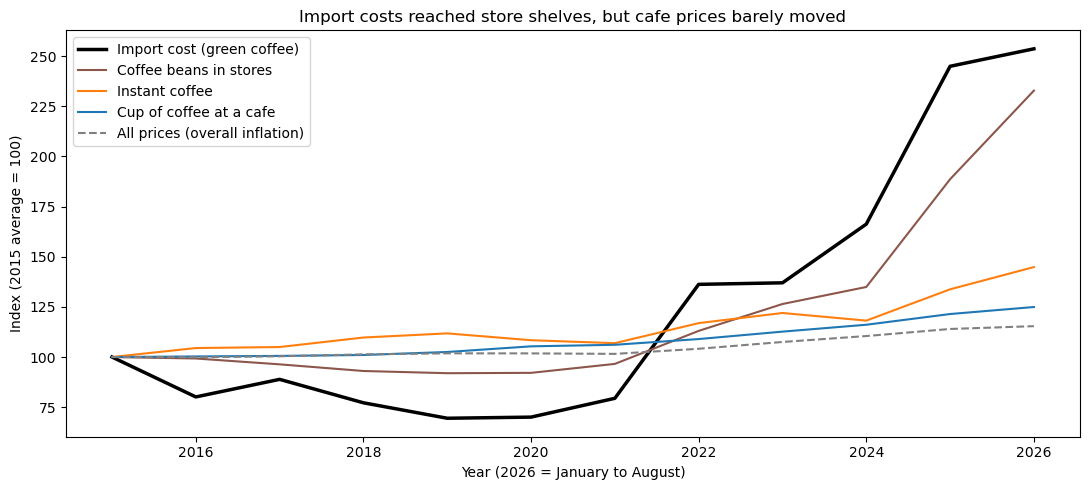

In [14]:
# One line per series, all indexed to 2015 = 100
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(cpi_index.index, cpi_index["import_cost"], label="Import cost (green coffee)", color="black", linewidth=2.5)
ax.plot(cpi_index.index, cpi_index["cpi_coffee_beans"], label="Coffee beans in stores", color="tab:brown")
ax.plot(cpi_index.index, cpi_index["cpi_instant_coffee"], label="Instant coffee", color="tab:orange")
ax.plot(cpi_index.index, cpi_index["cpi_cafe_coffee_coffee_shop"], label="Cup of coffee at a cafe", color="tab:blue")
ax.plot(cpi_index.index, cpi_index["cpi_all_items"], label="All prices (overall inflation)", color="gray", linestyle="--")

ax.set_title("Import costs reached store shelves, but cafe prices barely moved")
ax.set_ylabel("Index (2015 average = 100)")
ax.set_xlabel("Year (2026 = January to August)")
ax.legend()
plt.tight_layout()
plt.show()

**What it shows:**
- **"Rockets and feathers":** from 2016 to 2021, Japan's import cost fell by up to 31%, but store coffee beans fell only 8% and instant coffee actually rose. When costs rose after 2022, store prices followed, but over two to three years rather than right away.
- **The further from raw coffee, the smaller the increase.** By 2026, coffee beans were up about 133%, instant coffee about 45%, cafe coffee about 25%, and all prices about 15%. A bag of coffee is mostly coffee; a cup at a cafe is mostly rent, labor, and service.
- **"All items" is the benchmark:** coffee beans rose far faster than general inflation, while cafe coffee rose only a little faster.

## 9. City comparison: Naha vs. Tokyo, Kyoto, and Sapporo

Store and cafe prices in yen from the Retail Price Survey. The file is in **long format** (one row per month, city, and item), so `pivot_table` is used to make one column per city.

In [15]:
# ---------- Store and cafe prices by city ----------
# Source: Statistics Bureau of Japan, Retail Price Survey, prices by city (via e-Stat)
# Prices are in yen. Item codes: 1921 instant coffee, 1922 ground coffee (per 100g),
# 2162 cafe coffee at a coffee shop (per cup), 2165 self-service cafe coffee (per cup)
city = pd.read_csv(DATA + "/japan_coffee_retail_prices_by_city_2010_2026.csv")

# Convert "2010-01" text into real dates, and add a year column
city["month"] = pd.to_datetime(city["month"])
city["year"] = city["month"].dt.year

# Health check
print("CITY PRICES")
print("Shape:", city.shape)
print("Cities:", city["city"].unique())
print("Items:", city["item"].unique())
print("Missing prices:", city["price_yen"].isna().sum())

CITY PRICES
Shape: (2960, 7)
Cities: ['Kyoto' 'Naha' 'Sapporo' 'Tokyo (23 wards)']
Items: ['Instant coffee' 'Ground coffee (regular coffee)'
 'Cafe coffee, coffee shop' 'Cafe coffee, self-service chain']
Missing prices: 2


### Cafe coffee by city

Price of a cup of coffee (yen):
city  Kyoto   Naha  Sapporo  Tokyo (23 wards)
year                                         
2015  414.0  365.0    420.0             422.0
2016  415.0  378.0    420.0             434.0
2017  415.0  379.0    420.0             450.0
2018  418.0  381.0    420.0             479.0
2019  423.0  396.0    430.0             491.0
2020  442.0  403.0    449.0             512.0
2021  448.0  375.0    447.0             513.0
2022  466.0  377.0    452.0             520.0
2023  493.0  401.0    473.0             547.0
2024  542.0  390.0    492.0             571.0
2025  566.0  411.0    536.0             613.0
2026  597.0  434.0    558.0             629.0

Index (2015 = 100):
city  Kyoto   Naha  Sapporo  Tokyo (23 wards)
year                                         
2015  100.0  100.0    100.0             100.0
2016  100.0  104.0    100.0             103.0
2017  100.0  104.0    100.0             107.0
2018  101.0  105.0    100.0             114.0
2019  102.0  109.0    102.0

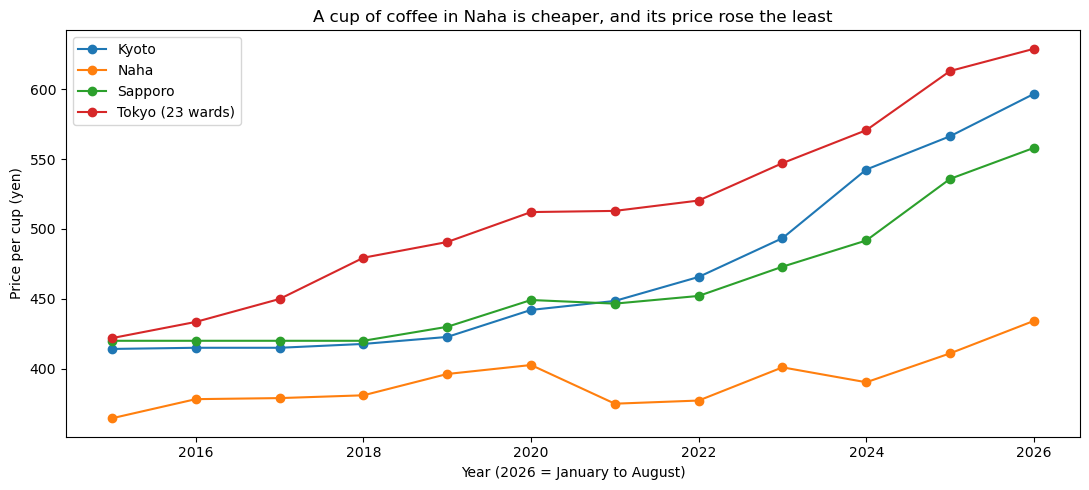

In [16]:
# Keep only cafe coffee at a coffee shop (item 2162)
cafe = city[city["item_code"] == 2162]

# pivot_table: rows = years, columns = cities, values = average price that year
cafe_yearly = cafe.pivot_table(index="year", columns="city", values="price_yen", aggfunc="mean")
cafe_yearly = cafe_yearly.loc[2015:]

print("Price of a cup of coffee (yen):")
print(cafe_yearly.round(0))
print()
print("Index (2015 = 100):")
print((cafe_yearly / cafe_yearly.loc[2015] * 100).round(0))

# One line per city
fig, ax = plt.subplots(figsize=(11, 5))
for c in cafe_yearly.columns:
    ax.plot(cafe_yearly.index, cafe_yearly[c], label=c, marker="o")

ax.set_title("A cup of coffee in Naha is cheaper, and its price rose the least")
ax.set_ylabel("Price per cup (yen)")
ax.set_xlabel("Year (2026 = January to August)")
ax.legend()
plt.tight_layout()
plt.show()

**What it shows:** Naha has the cheapest cafe coffee, and its price rose only about 19% since 2015, compared with 49% in Tokyo and 44% in Kyoto. The gap between Naha and Tokyo grew from 57 yen to 195 yen per cup. Tokyo was already up 22% by 2021, before import costs jumped, which points to local costs such as rent and wages.

*Possible explanations (hypotheses, not tested here):* lower wages and rents in Okinawa; Kyoto's 2023 to 2025 jump may reflect the tourism boom after Japan reopened in late 2022; Naha's 2021 dip may reflect the collapse of Okinawa tourism during COVID. Each city's price is an average of a small number of surveyed shops, so single-year changes can partly be noise.

### Store-bought ground coffee by city

Price of ground coffee (yen per 100g):
city  Kyoto   Naha  Sapporo  Tokyo (23 wards)
year                                         
2015  144.0  161.0    139.0             150.0
2016  138.0  153.0    144.0             149.0
2017  132.0  134.0    133.0             147.0
2018  133.0  137.0    133.0             141.0
2019  131.0  152.0    136.0             137.0
2020  129.0  150.0    132.0             136.0
2021  139.0  153.0    138.0             140.0
2022  157.0  162.0    162.0             160.0
2023  174.0  191.0    184.0             177.0
2024  195.0  191.0    197.0             189.0
2025  254.0  270.0    267.0             266.0
2026  334.0  331.0    346.0             339.0

Index (2015 = 100):
city  Kyoto   Naha  Sapporo  Tokyo (23 wards)
year                                         
2015  100.0  100.0    100.0             100.0
2016   96.0   95.0    103.0              99.0
2017   92.0   83.0     95.0              98.0
2018   93.0   86.0     96.0              94.0
2019   91.0   94.0  

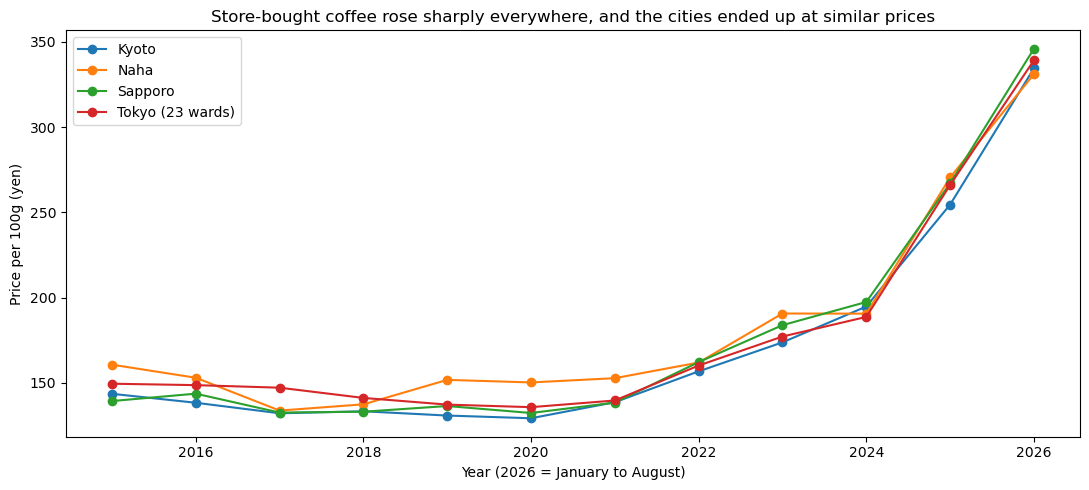

In [17]:
# Item 1922: regular ground coffee in a bag, price per 100g
# Note: the surveyed bag size shrank over time (450-500g in 2010, 200-260g by 2026),
# so part of the per-100g increase is smaller bags ("shrinkflation"), not just coffee costs
beans = city[city["item_code"] == 1922]

beans_yearly = beans.pivot_table(index="year", columns="city", values="price_yen", aggfunc="mean")
beans_yearly = beans_yearly.loc[2015:]

print("Price of ground coffee (yen per 100g):")
print(beans_yearly.round(0))
print()
print("Index (2015 = 100):")
print((beans_yearly / beans_yearly.loc[2015] * 100).round(0))

fig, ax = plt.subplots(figsize=(11, 5))
for c in beans_yearly.columns:
    ax.plot(beans_yearly.index, beans_yearly[c], label=c, marker="o")

ax.set_title("Store-bought coffee rose sharply everywhere, and the cities ended up at similar prices")
ax.set_ylabel("Price per 100g (yen)")
ax.set_xlabel("Year (2026 = January to August)")
ax.legend()
plt.tight_layout()
plt.show()

**What it shows:** store-bought coffee more than doubled in every city, and the cities moved closer together (a 22 yen spread in 2015 vs. 15 yen in 2026). Naha went from the most expensive city in 2015 to the cheapest in 2026. A likely factor is that a fixed shipping premium to Okinawa matters less once coffee itself is much more expensive. Part of the 2025 to 2026 jump reflects the smaller bag size surveyed from May 2026.

## 10. Summary of findings

1. **The yen flipped from shield to amplifier.** In 2011 to 2013, a strong yen softened a global price spike for Japan. Since 2022, a weak yen has pushed Japanese coffee costs above what dollar prices alone would explain.
2. **Japan's import cost follows world prices, about 3 months later,** supporting the assumption that coffee is bought at dollar prices.
3. **The main breakdown:** since 2015, Japan's coffee import cost has risen about 2.5 times. In 2025, about two-thirds of the increase came from world coffee prices and one-third from the weaker yen. In 2023 and 2024, the exchange rate mattered about as much as the coffee market.
4. **Pass-through to consumers:** store-bought beans eventually followed the import cost, more than doubling, while cafe coffee rose only about 25%. When import costs fell in the late 2010s, store prices hardly came down ("rockets and feathers").
5. **Okinawa:** store coffee in Naha followed the national trend, but Naha's cafe prices rose only 19% since 2015, compared with 49% in Tokyo, and the gap between them more than tripled.

**Limitations:** Japan's import cost is a blend of many countries and grades; dollar import prices are estimated from yearly average exchange rates; recent Customs data is preliminary; surveyed coffee bag sizes changed over time; city prices come from a small number of shops.